# So sánh RNN, LSTM và Transformer
Chạy sau 01, 02, 03 (đọc `outputs/*_results.json`).

In [1]:
import json
import pandas as pd
import common as C
L = lambda n: json.load(open(C.OUT_DIR / f'{n}_results.json'))

## Bài toán chuỗi thời gian (ngắn): RNN đủ dùng
Dự báo nhiệt độ ngày mai từ 30 ngày trước. Sai số càng thấp càng tốt.

In [2]:
import numpy as np
_, info = C.load_temperature()
rows = C.baselines(info)
for k, n in (('RNN', 'rnn_temp'), ('LSTM', 'lstm_temp')):
    r = L(n); rows[k] = {'MAE': r['MAE'], 'RMSE': r['RMSE'], 'tham số (M)': r['params_M'], 'thời gian train (s)': r['train_time_s']}
pd.DataFrame(rows).T.round(3)

,MAE,RMSE,tham số (M),thời gian train (s)
persistence (hom qua),2.036,2.572,NaN,NaN
trung binh 7 ngay,1.968,2.540,NaN,NaN
RNN,1.730,2.209,0.013,3.682
LSTM,1.714,2.194,0.050,3.896


## Bài toán văn bản dài (IMDB): LSTM thắng RNN, Transformer thắng tất cả
Độ chính xác trên 25.000 review test.

In [3]:
stress = {k: {int(l): v for l, v in d.items()} for k, d in json.load(open(C.OUT_DIR / 'length_stress.json')).items()}
rows = {
    'RNN 1 chiều (400 từ)': {'accuracy': stress['rnn'][400]},
    'LSTM 1 chiều (400 từ)': {'accuracy': stress['lstm'][400]},
}
for k, n in (('BiLSTM (400 từ)', 'lstm_imdb'), ('DistilBERT (256 token)', 'distilbert_imdb')):
    r = L(n); rows[k] = {'accuracy': r['test_acc'], 'macro F1': r['macro_f1'], 'tham số (M)': r['params_M'], 'thời gian train (phút)': r['train_time_s'] / 60}
pd.DataFrame(rows).T.round(4)

,accuracy,macro F1,tham số (M),thời gian train (phút)
RNN 1 chiều (400 từ),0.7861,NaN,NaN,NaN
LSTM 1 chiều (400 từ),0.8613,NaN,NaN,NaN
BiLSTM (400 từ),0.8766,0.8766,2.8247,1.4328
DistilBERT (256 token),0.9159,0.9159,66.9550,9.5258


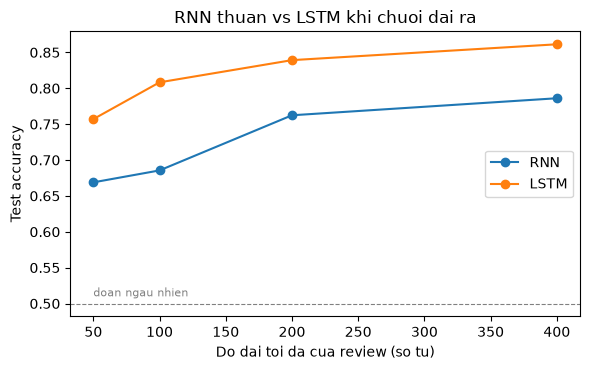

In [4]:
C.plot_stress(stress)

## Tóm tắt thế mạnh và điểm yếu

| | RNN | LSTM | Transformer |
|---|---|---|---|
| Thế mạnh | Đơn giản, nhẹ, nhanh | Nhớ thông tin xa nhờ cổng và cell state | Attention nhìn toàn chuỗi, song song, có pretrained |
| Điểm yếu | Gradient tiêu biến trên chuỗi dài | Vẫn xử lý tuần tự nên chậm hơn; nhớ tốt nhưng không vô hạn | Tốn bộ nhớ O(n²) theo độ dài; cần nhiều dữ liệu nếu train từ đầu |
| Hợp với | Chuỗi ngắn, phụ thuộc gần (dự báo ngắn hạn) | Chuỗi dài vừa, dữ liệu vừa phải | Văn bản, dữ liệu lớn, có mô hình pretrained |

## Kết luận

| Bài toán | Kết quả |
|---|---|
| **Chuỗi thời gian ngắn** (nhiệt độ ngày mai) | RNN (MAE 1,730 °C) và LSTM (1,714 °C) gần như bằng nhau, cùng tốt hơn persistence (2,036 °C) khoảng 15%. RNN chỉ có 12,7 nghìn tham số, bằng khoảng một phần tư LSTM. |
| **Văn bản IMDB** | RNN 1 chiều 78,6%, LSTM 1 chiều 86,1%, BiLSTM 87,7%, DistilBERT **91,6%** (accuracy trên 25.000 review test, tất cả cùng độ dài 400 từ hoặc 256 token). |

1. **RNN:** đủ tốt và rất rẻ khi chuỗi ngắn, phụ thuộc gần (dự báo ngắn hạn). Trên văn bản dài, RNN thuần kém hơn rõ rệt (78,6% so với 86,1% của LSTM cùng cấu hình).
2. **LSTM:** ổn định và mạnh hơn RNN thuần ở mọi độ dài review thử (hơn 7,5 đến 12,3 điểm accuracy). **Lưu ý:** khoảng cách này **không tăng** theo độ dài, nên thí nghiệm không chứng minh riêng khả năng "nhớ xa". Cần bài toán có phụ thuộc xa thật sự để kiểm chứng điều đó.
3. **Transformer:** chính xác nhất (91,6%) và đoán đúng cả hai câu có chuyển ý mà BiLSTM sai. Đổi lại có số tham số gấp khoảng 24 lần và thời gian train gấp khoảng 6,6 lần BiLSTM. Mức vượt trội đến từ cả kiến trúc attention và việc pretrained, không tách riêng được.
4. **Chọn mô hình theo bài toán:** chuỗi ngắn và nhẹ chọn RNN; chuỗi dài vừa phải, dữ liệu vừa phải chọn LSTM; văn bản và có mô hình pretrained sẵn thì chọn Transformer.

*Tất cả kết quả là một lần chạy với một seed. Chênh lệch nhỏ (như RNN và LSTM trên chuỗi thời gian) không đủ để kết luận mô hình nào hơn.*